<a href="https://colab.research.google.com/github/Murcha1990/GenModels_AI26/blob/main/Seminars_Base/Sem4_Diffusion_MetricLearning/StableDiffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install diffusers -q

In [2]:
import torch
import torchvision
from diffusers import DDPMScheduler, UNet2DModel
from matplotlib import pyplot as plt
from torch import nn
from torch.utils.data import DataLoader
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


# Stable Diffusion

Stable Diffusion основана на определенном типе диффузионных моделей **Latent Diffusion**, предложеном в [High-Resolution Image Synthesis with Latent Diffusion Models](https://arxiv.org/abs/2112.10752).

Подход использует latent diffusion, что позволяет снизить сложность по памяти и вычислениям за счет того, что мы запускаем диффузионные процессы в низкоразмерном латентом пространстве вместо исходного простраства изображений. В этом и заключается главное различие латентных моделей.

Весь пайплайн состоит из трех основных комнонентов:

1. Автокодировщика (VAE).
2. [U-Net](https://colab.research.google.com/github/huggingface/notebooks/blob/main/diffusers/diffusers_intro.ipynb#scrollTo=wW8o1Wp0zRkq).
3. Текстового кодировщика, например [CLIP's Text Encoder](https://huggingface.co/docs/transformers/model_doc/clip#transformers.CLIPTextModel).

Цель: модель учится восстанавливать изображение из зашумлённого латентного представления, руководствуясь текстовым описанием.

### Обучение модели

1. Сбор данных

- Берутся пары: изображение + текстовое описание.

- Текст пропускается через текстовый энкодер CLIP. На выходе — текстовый эмбеддинг (вектор), описывающий смысл фразы.

2. Преобразование изображений

- Каждое изображение кодируется VAE-энкодером в латентное пространство (компактное представление).

3. Добавление шума

- В латентное изображение постепенно добавляют шум на каждом шаге (процесс зашумления).

4. Обучение обратного процесса. U-Net получает на вход:

- зашумлённое латентное изображение

- номер шага (t)

- текстовый эмбеддинг CLIP

Задача сети — предсказать добавленный шум.

### Inference

1. Пользовательский промпт проходит через тот же CLIP-текст-энкодер → создаётся эмбеддинг текста.

2. Инициализация шума. Генерация начинается с случайного латентного тензора (полностью шумного).

3. Пошаговое расшумление. На каждом шаге U-Net получает:

- текущий зашумлённый латент

- номер шага

- CLIP-эмбеддинг

Модель постепенно убирает шум, добавляя детали, которые соответствуют тексту.

4. Декодирование. После последнего шага результат декодируется обратно в изображение через VAE-декодер.

Итог — изображение, визуально согласованное с CLIP-представлением текста.

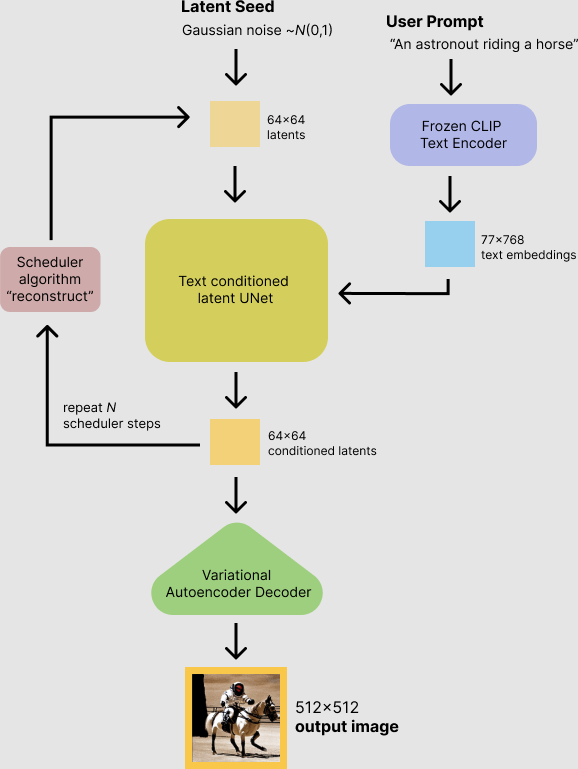

Далее по шагам обсудим схему работы Stable Diffusion, используя изображения ис [статьи](https://stable-diffusion-art.com/how-stable-diffusion-work/).

## Вариационный автокодировщик (VAE)

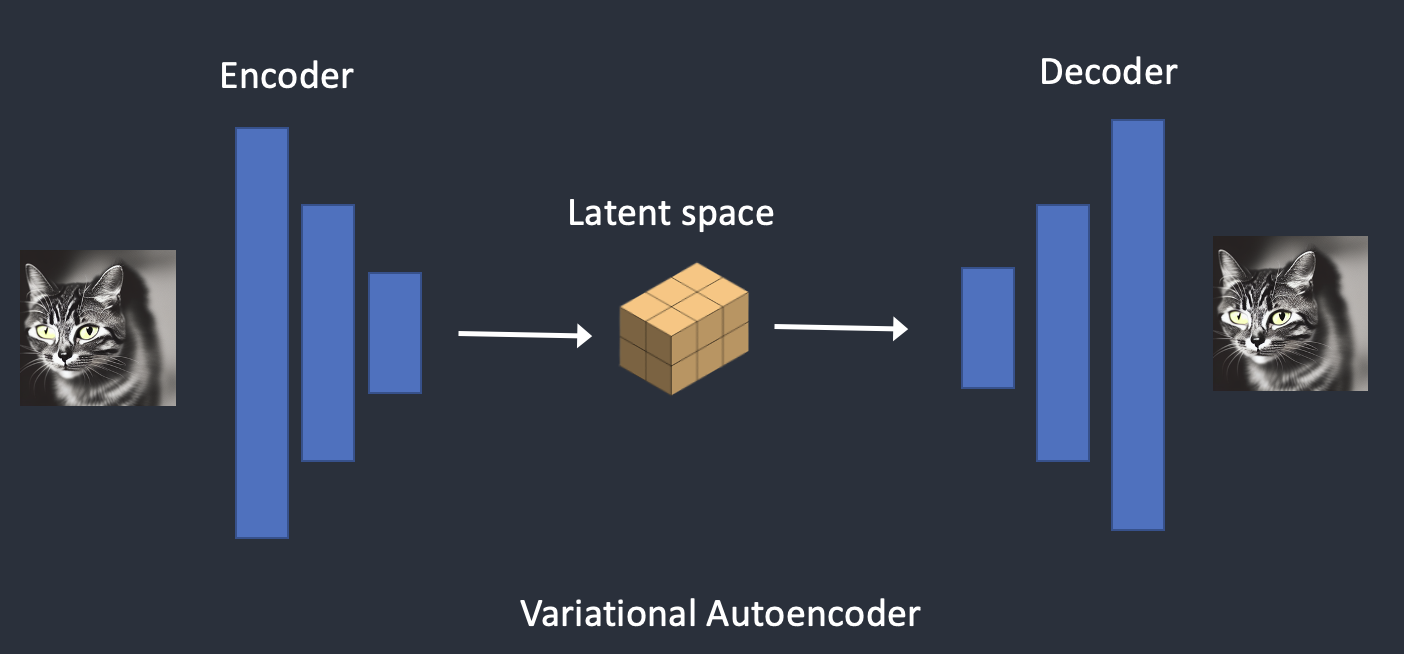

## Текстовый кодировщик (CLIP)

Мы можем обусловить нашу модель на текст (conditioned model) по аналогии с добавлением меток в сеть для генерации MNIST.

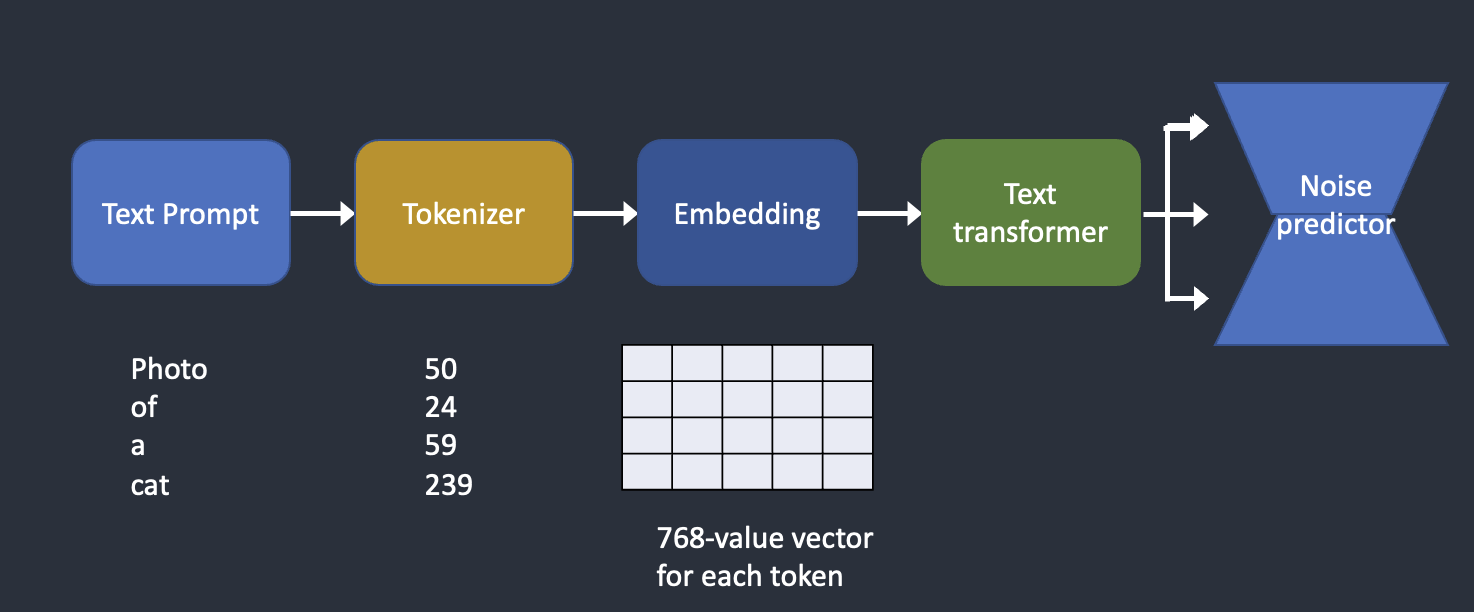

## Схема работы Stable Diffusion

На каждом шаге генерации (расшумления) в Stable Diffusion происходит следующее:

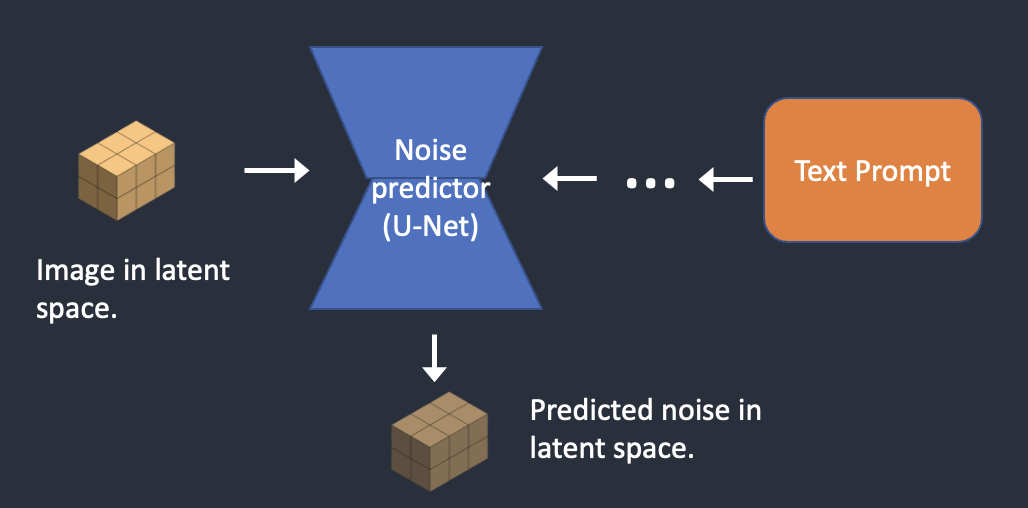

Расшумление - это процесс вычитания шума из изображения:

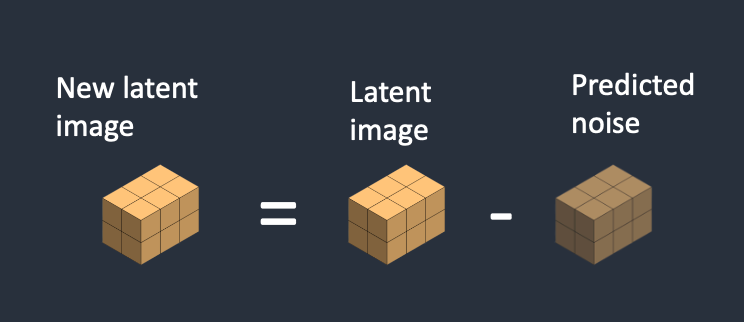

После нескольких (100-1000) шагов расшумления при помощи VAE-декодировщика получаем итоговое изображение:

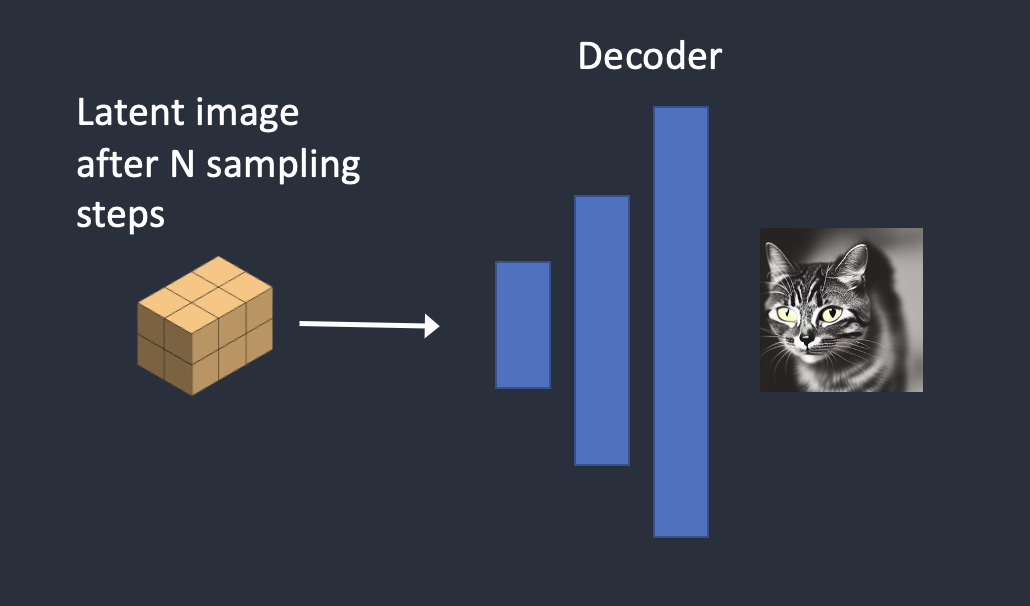

CLIP-эмбеддинги добавляются к текущему "шуму" через cross-attention:

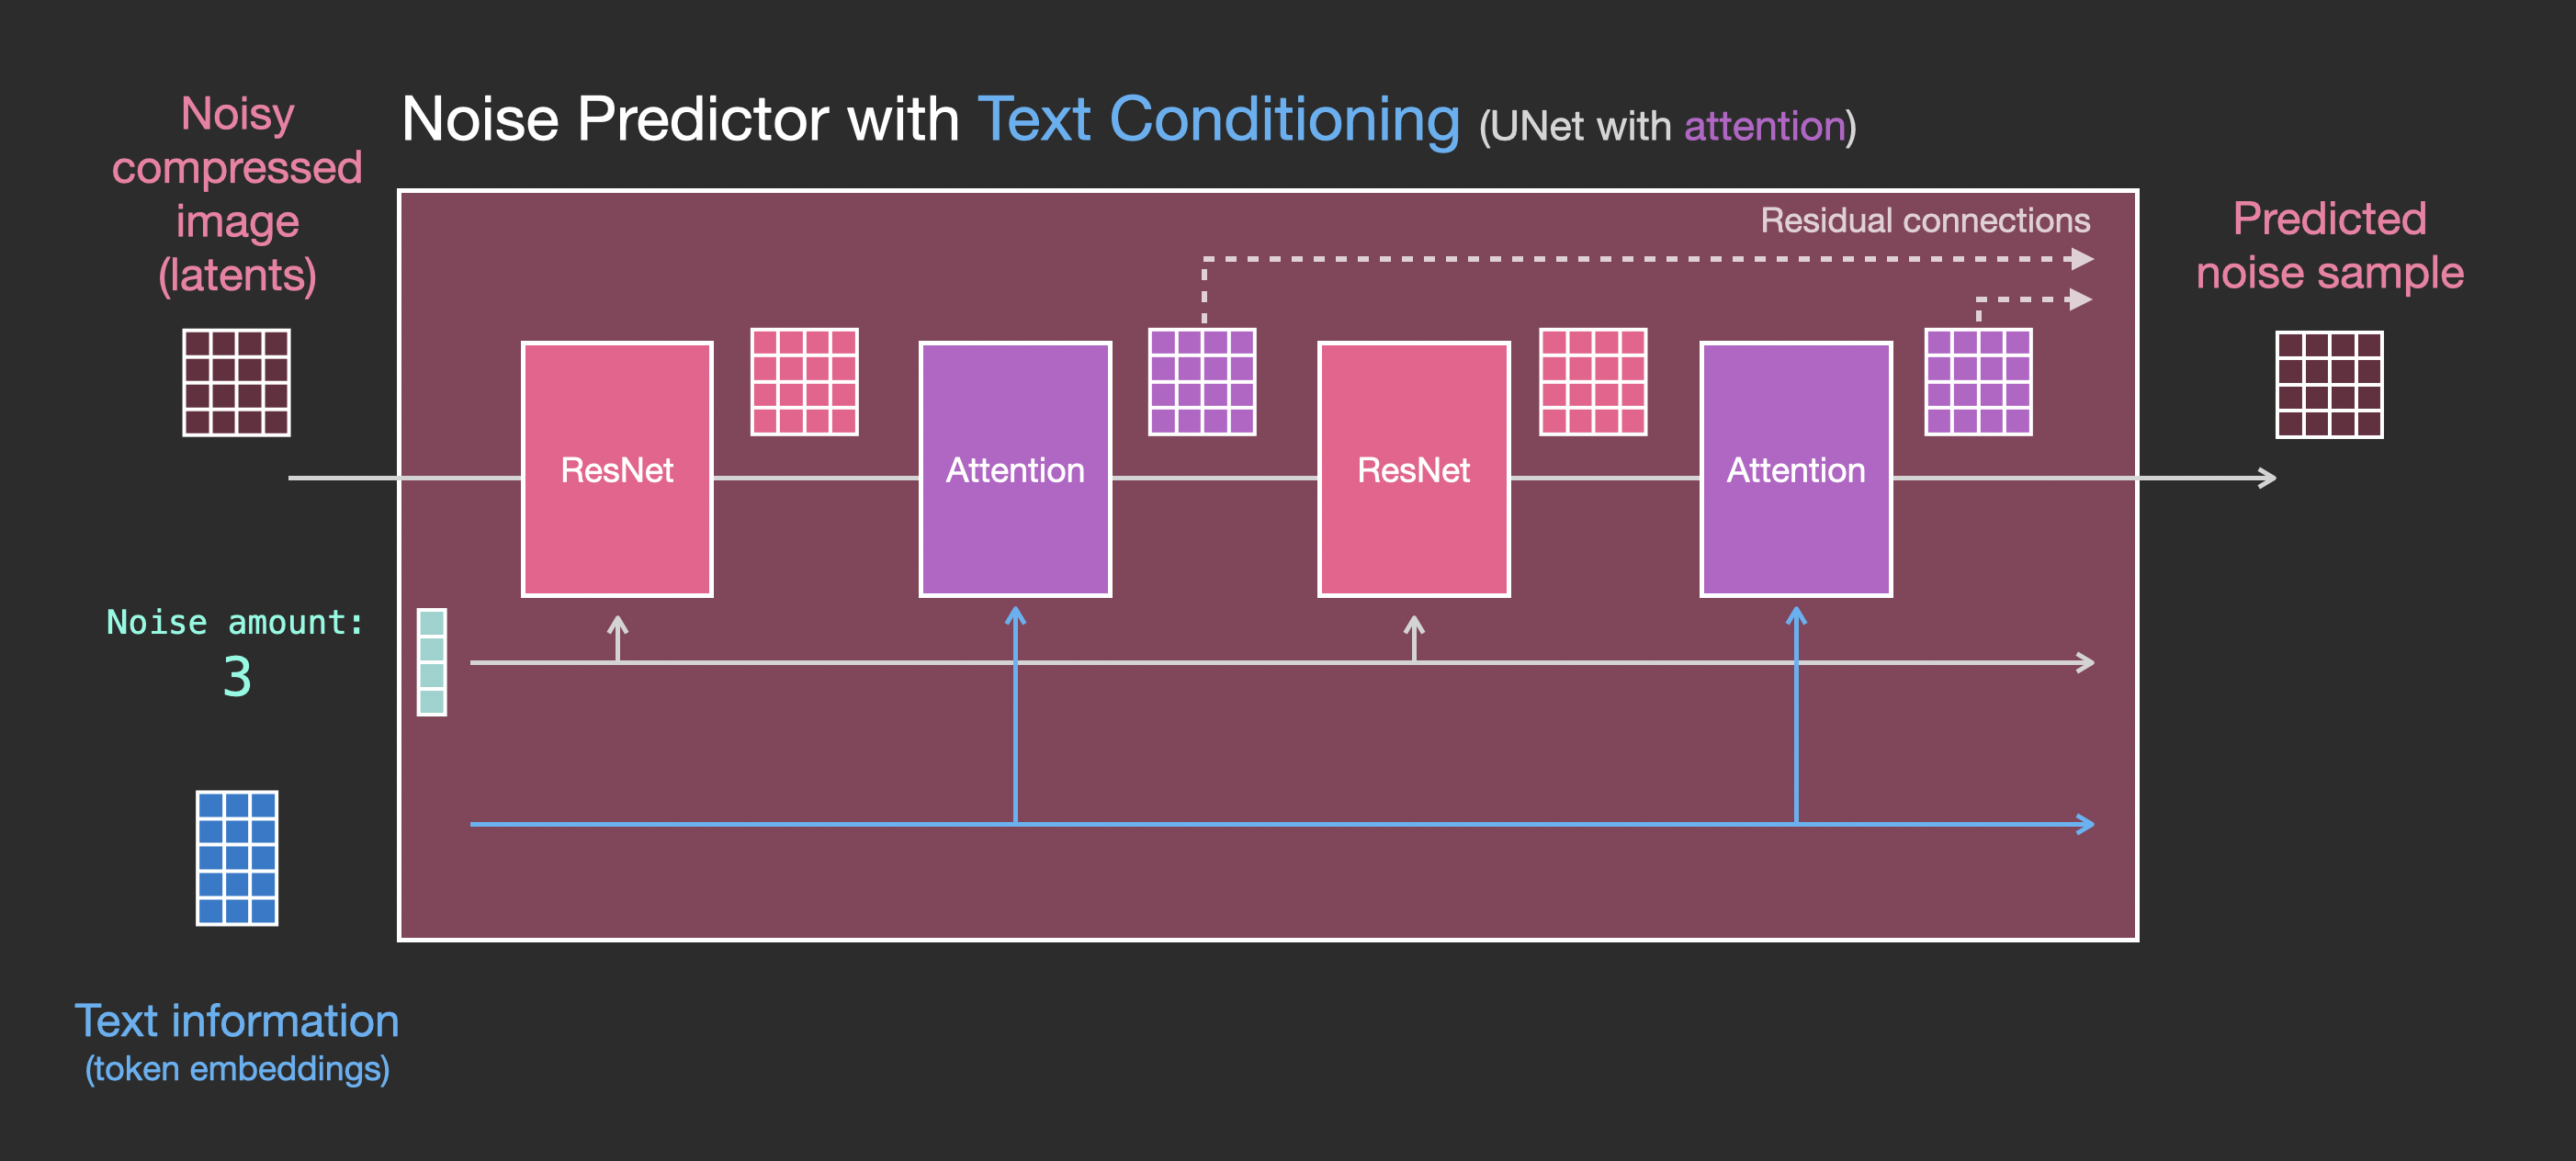

In [3]:
!pip install accelerate -q

In [4]:
from transformers import CLIPTextModel, CLIPTokenizer
from diffusers import AutoencoderKL, UNet2DConditionModel, PNDMScheduler

# 1. Загрузим автокодировщик, который будем использовать для декодирования изображений из латентного представления.
vae = AutoencoderKL.from_pretrained("CompVis/stable-diffusion-v1-4", subfolder="vae")

# 2. Загрузим текстовый токенайзер и кодировщик для обработки описания изображения
tokenizer = CLIPTokenizer.from_pretrained("openai/clip-vit-large-patch14")
text_encoder = CLIPTextModel.from_pretrained("openai/clip-vit-large-patch14")

# 3. Загрузим UNet модель для диффузионных процессов.
unet = UNet2DConditionModel.from_pretrained("CompVis/stable-diffusion-v1-4", subfolder="unet")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/551 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B /  335MB            

vae/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

[transformers] CLIPTextModel LOAD REPORT from: openai/clip-vit-large-patch14
Key                                                            | Status     |  | 
---------------------------------------------------------------+------------+--+-
vision_model.encoder.layers.{0...23}.mlp.fc2.weight            | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.mlp.fc2.bias              | UNEXPECTED |  | 
vision_model.post_layernorm.bias                               | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.q_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.v_proj.bias     | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.mlp.fc1.bias              | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.layer_norm2.bias          | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.layer_norm2.weight        | UNEXPECTED |  | 
vision_model.encoder.layers.{0...23}.self_attn.q_proj.weight   | UNEXPECTED |  | 
vision_model.encoder.

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 3.44GB            

unet/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

In [5]:
vae = vae.to(device)
text_encoder = text_encoder.to(device)
unet = unet.to(device)

In [6]:
prompt = ["""masterpiece, best quality, ultra-detailed, deep space around an astronaut riding a horse, highly detailed lighting and shadows"""]
# prompt = ["""Black cat in roses."""]

height = 512
width = 512

num_inference_steps = 100

guidance_scale = 10

generator = torch.manual_seed(32)

batch_size = 1

Отобразим наше текстовое описание в пространство эмбеддингов с помощью текстового энкодера.

In [7]:
text_input = tokenizer(prompt, padding="max_length", max_length=tokenizer.model_max_length, truncation=True, return_tensors="pt")

with torch.no_grad():
  text_embeddings = text_encoder(text_input.input_ids.to(device))[0]

Создадим еще один вход для нашей модели. Подробнее о том, что такое  [classifier-free guidance](https://arxiv.org/abs/2207.12598).

In [8]:
max_length = text_input.input_ids.shape[-1]
uncond_input = tokenizer(
    [""] * batch_size, padding="max_length", max_length=max_length, return_tensors="pt"
)
with torch.no_grad():
  uncond_embeddings = text_encoder(uncond_input.input_ids.to(device))[0]

In [9]:
text_embeddings = torch.cat([uncond_embeddings, text_embeddings])

Сэмплируем шум для начала нашего диффузионного процесса.

In [10]:
latents = torch.randn(
  (batch_size, unet.in_channels, height // 8, width // 8),
  generator=generator,
)
latents = latents.to(device)
latents.shape

/tmp/ipykernel_475/1881358676.py:2: FutureWarning: Accessing config attribute `in_channels` directly via 'UNet2DConditionModel' object attribute is deprecated. Please access 'in_channels' over 'UNet2DConditionModel's config object instead, e.g. 'unet.config.in_channels'.
  (batch_size, unet.in_channels, height // 8, width // 8),


torch.Size([1, 4, 64, 64])

Используем `scheduler` для создания входа модели, учитывающего `timestep`.



In [11]:
from diffusers import LMSDiscreteScheduler

scheduler = LMSDiscreteScheduler(beta_start=0.00085, beta_end=0.012, beta_schedule="scaled_linear", num_train_timesteps=1000)
scheduler.set_timesteps(num_inference_steps)

In [12]:
latents = latents * scheduler.init_noise_sigma

Запускаем диффузионный процесс в латентном пространстве.

In [13]:
from tqdm.auto import tqdm
from torch import autocast

for t in tqdm(scheduler.timesteps):
  # expand the latents if we are doing classifier-free guidance to avoid doing two forward passes.
  latent_model_input = torch.cat([latents] * 2)

  latent_model_input = scheduler.scale_model_input(latent_model_input, t)

  # predict the noise residual
  with torch.no_grad():
    noise_pred = unet(latent_model_input, t, encoder_hidden_states=text_embeddings).sample

  # perform guidance
  noise_pred_uncond, noise_pred_text = noise_pred.chunk(2)
  noise_pred = noise_pred_uncond + guidance_scale * (noise_pred_text - noise_pred_uncond)

  # compute the previous noisy sample x_t -> x_t-1
  latents = scheduler.step(noise_pred, t, latents).prev_sample

  0%|          | 0/100 [00:00<?, ?it/s]

Используем автокодировщик для того, чтобы восстановить изображение из полученного латентного представления после завершения диффузионного процесса.

In [14]:
# scale and decode the image latents with vae
latents = 1 / 0.18215 * latents

with torch.no_grad():
  image = vae.decode(latents).sample

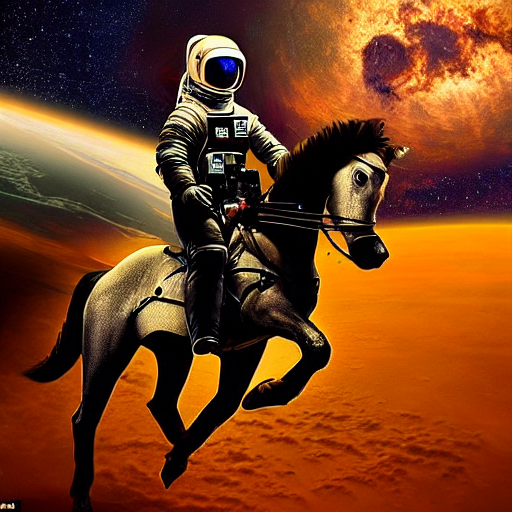

In [15]:
from PIL import Image

image = (image / 2 + 0.5).clamp(0, 1)
image = image.detach().cpu().permute(0, 2, 3, 1).numpy()
images = (image * 255).round().astype("uint8")
pil_images = [Image.fromarray(image) for image in images]
pil_images[0]

## Classifier-Free Guidance (CFG)

Для CFG модель при обучении должна научиться предсказывать шум как с текстовым условием, так и без него. Для этого часть текстовых промптов случайным образом заменяют пустыми строками.

**Роль пустого промпта.** Пустой промпт задаёт baseline — предсказание шума без конкретного текстового условия. При этом модель по-прежнему использует выученные закономерности изображений.

**Смысл разности предсказаний.** Разность $\epsilon_c-\epsilon_u$ показывает, как меняется предсказание шума при добавлении текстового условия. CFG усиливает это изменение, чтобы генерация сильнее следовала промпту.

На инференсе предсказания объединяются:

$$
\epsilon_{\text{CFG}}=\epsilon_u+s(\epsilon_c-\epsilon_u),
$$

где $\epsilon_u$ — предсказание для пустого промпта, $\epsilon_c$ — для исходного промпта, а $s$ — `guidance_scale`. При $s>1$ влияние текстового условия усиливается.

Сама формула CFG применяется на инференсе, а обучение с пустыми промптами позволяет модели формировать оба необходимых предсказания.